# Descomposición de las series temporales

En este notebook se analiza la estructura temporal de las variables ICEN, ONI, SSN y precipitación ERA5.

Se utiliza la descomposición STL para separar cada serie en:

- tendencia;
- componente estacional;
- residuo.

Debido a que las observaciones presentan frecuencia mensual, inicialmente se emplea un periodo estacional de 12 meses.

La descomposición tiene un propósito exploratorio y no implica que todas las variables presenten necesariamente una estacionalidad anual significativa.

In [4]:
import os
import subprocess

repo = "correlacion_actividad_solar_elnino"
ruta_repo = f"/content/{repo}"

if not os.path.exists(ruta_repo):
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/gretadive/correlacion_actividad_solar_elnino.git"
        ],
        check=True
    )
    print("✅ Repositorio clonado")
else:
    print("✅ Repositorio disponible")

✅ Repositorio disponible


In [6]:
%cd /content/correlacion_actividad_solar_elnino

/content/correlacion_actividad_solar_elnino


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = pd.read_csv(
    "data/processed/dataset_integrado_precipitacion.csv",
    parse_dates=["fecha"]
)

dataset = dataset.sort_values("fecha")
dataset = dataset.set_index("fecha")

dataset.head()

,anio,mes,ICEN,ONI,SSN,precipitacion_mm
fecha,,,,,,
1950-01-01,1950,1,-0.75,-1.32,143.9,155.309817
1950-02-01,1950,2,-1.07,-1.20,134.3,164.955825
1950-03-01,1950,3,-1.25,-1.12,155.4,158.180623
1950-04-01,1950,4,-1.18,-1.08,160.6,221.687990
1950-05-01,1950,5,-1.22,-1.10,150.5,123.802819


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

dataset = pd.read_csv(
    "data/processed/dataset_integrado_precipitacion.csv",
    parse_dates=["fecha"]
)

dataset = dataset.sort_values("fecha")
dataset = dataset.set_index("fecha")

In [11]:
stl_precip = STL(
    dataset["precipitacion_mm"],
    period=12,
    robust=True
)

resultado_precip = stl_precip.fit()

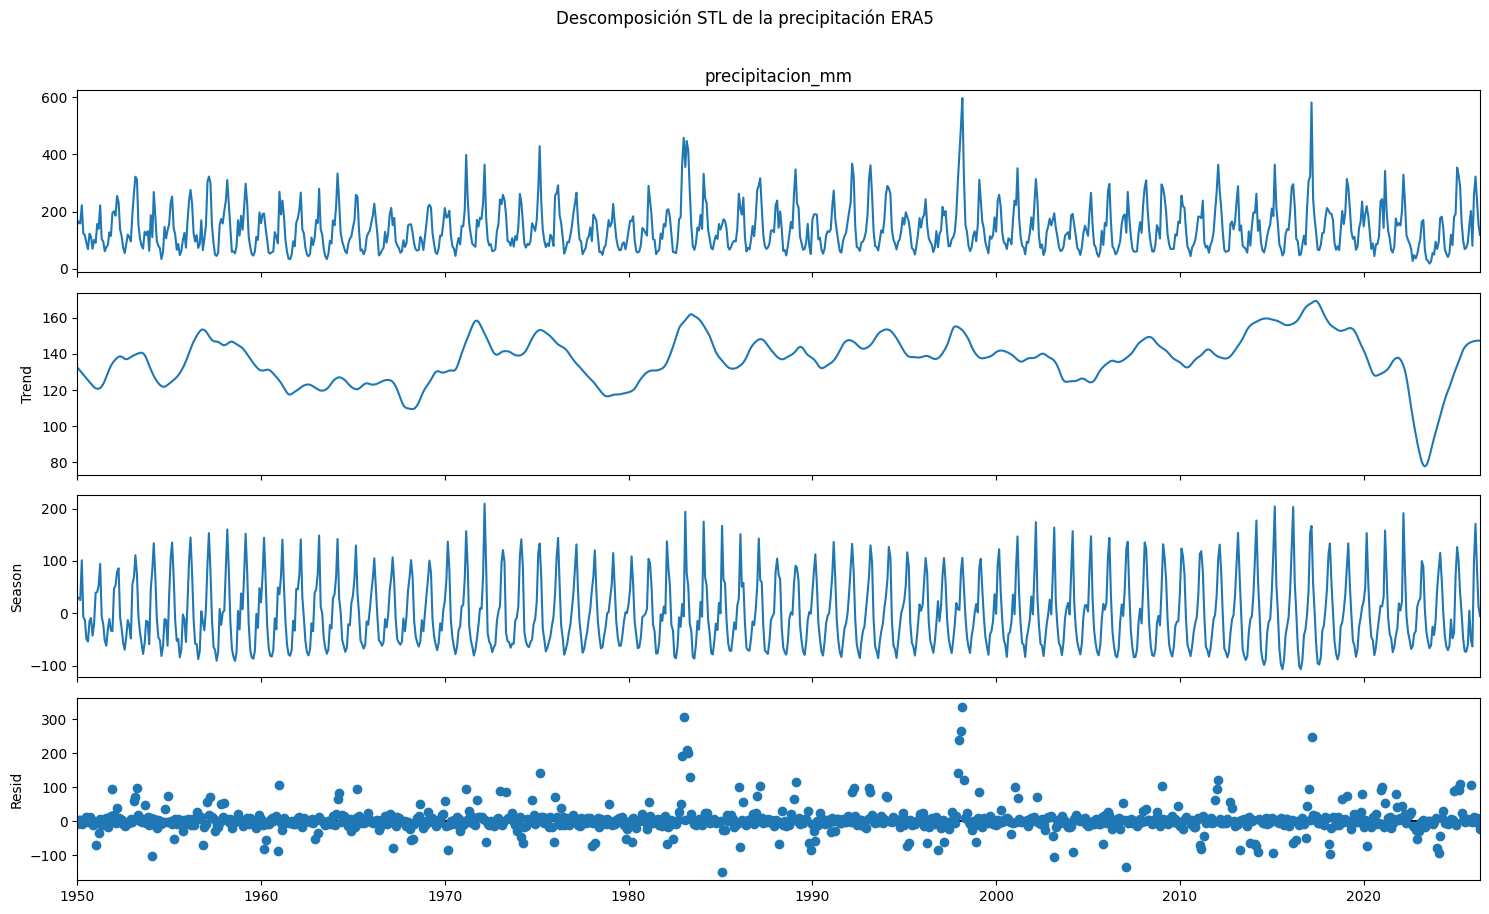

In [12]:
fig = resultado_precip.plot()
fig.set_size_inches(15, 9)

plt.suptitle(
    "Descomposición STL de la precipitación ERA5",
    y=1.01
)

plt.tight_layout()
plt.show()

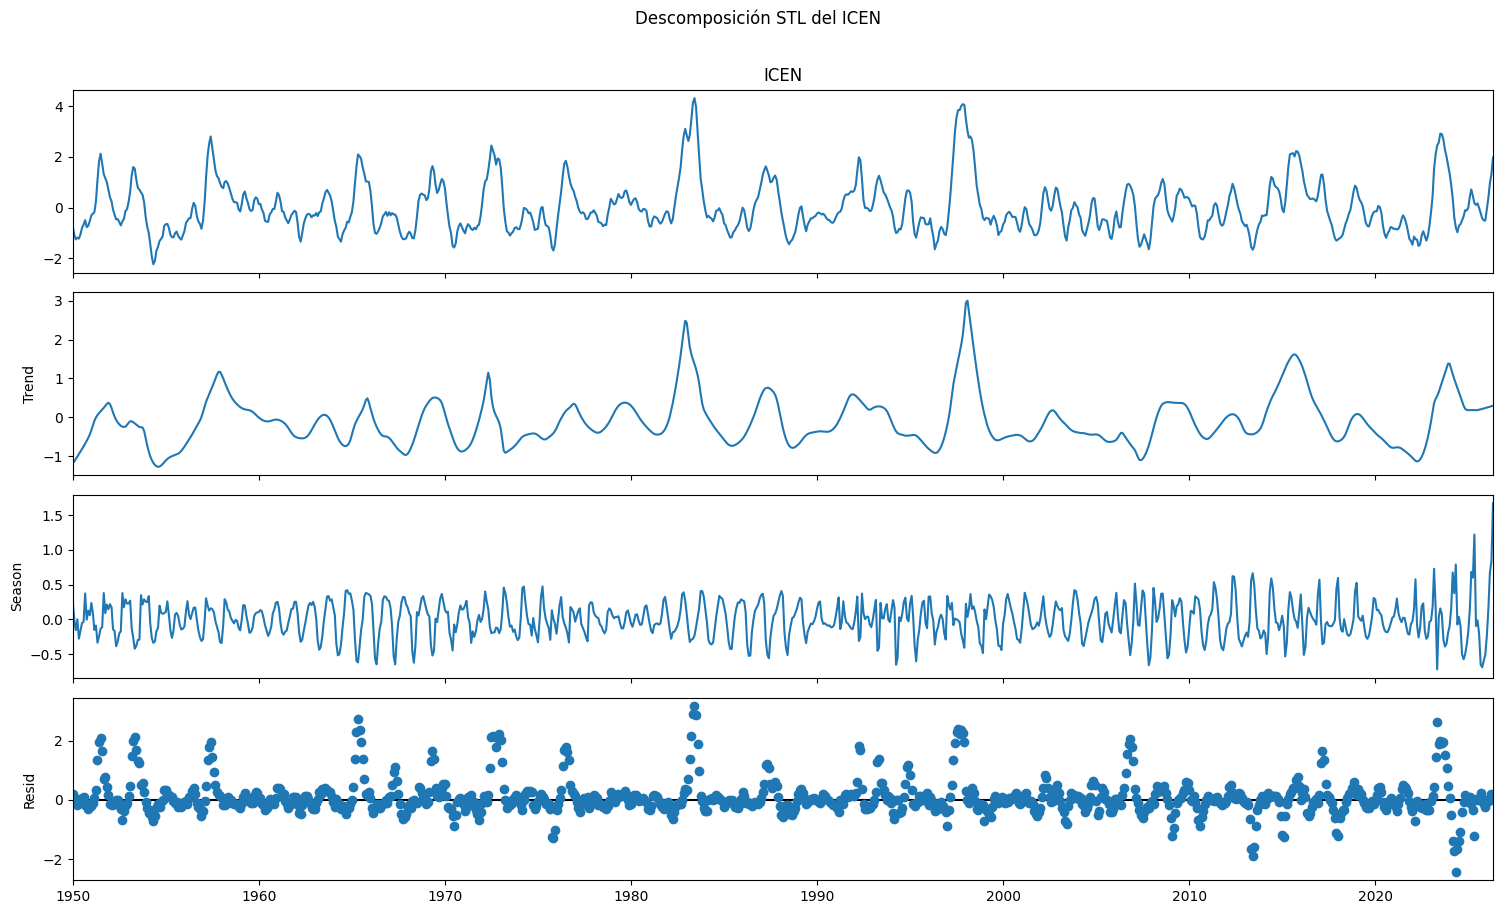

In [13]:
stl_icen = STL(
    dataset["ICEN"],
    period=12,
    robust=True
)

resultado_icen = stl_icen.fit()

fig = resultado_icen.plot()
fig.set_size_inches(15, 9)

plt.suptitle(
    "Descomposición STL del ICEN",
    y=1.01
)

plt.tight_layout()
plt.show()

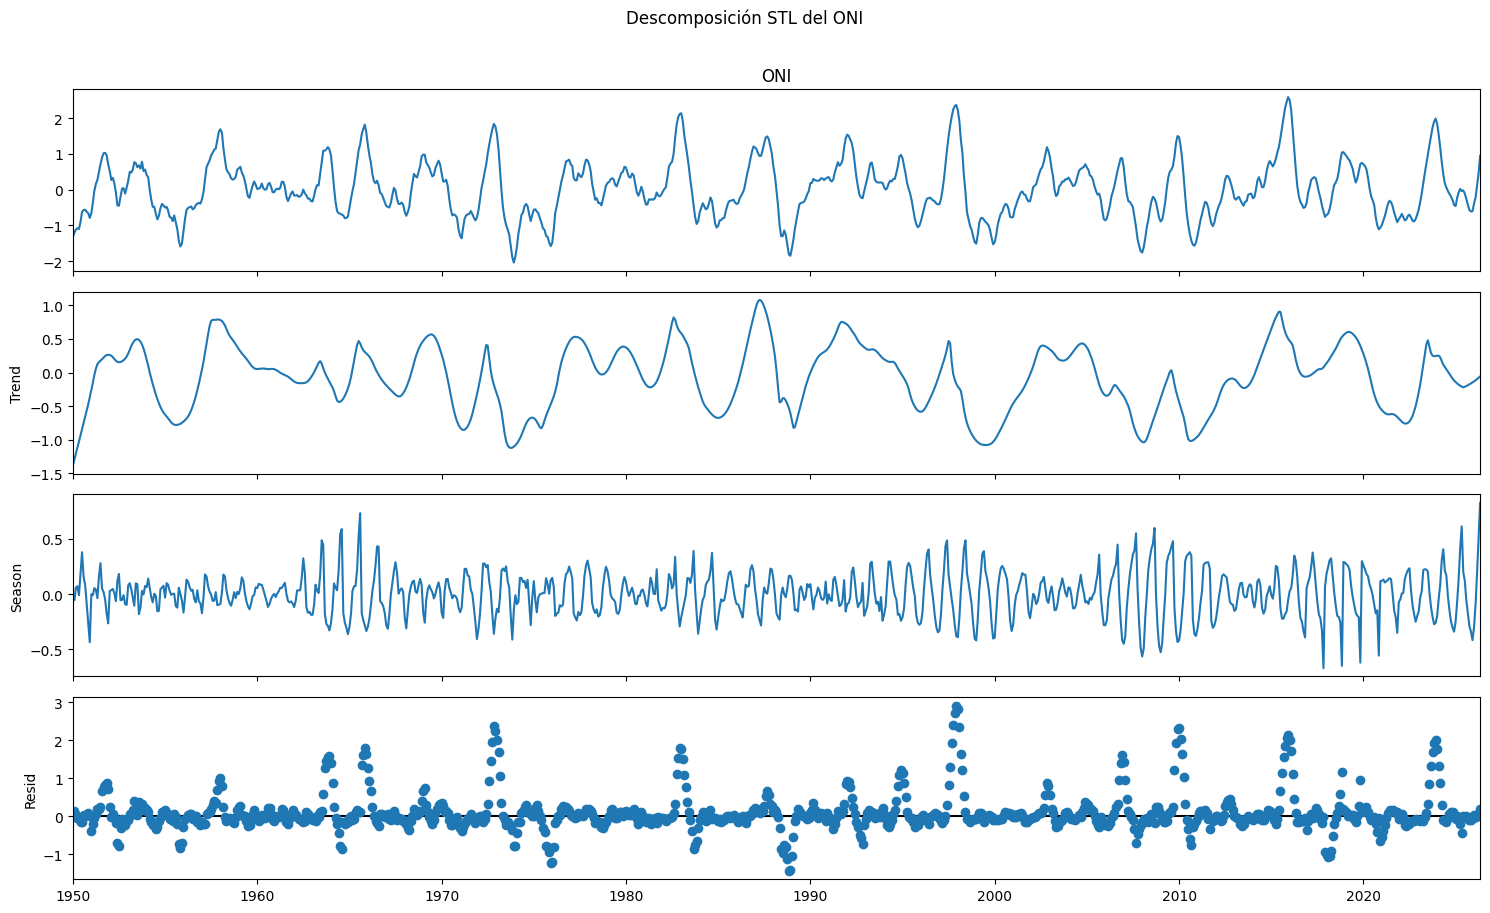

In [14]:
stl_oni = STL(
    dataset["ONI"],
    period=12,
    robust=True
)

resultado_oni = stl_oni.fit()

fig = resultado_oni.plot()
fig.set_size_inches(15, 9)

plt.suptitle(
    "Descomposición STL del ONI",
    y=1.01
)

plt.tight_layout()
plt.show()

## Conclusión

La precipitación ERA5 presenta una componente estacional anual claramente definida.

En contraste, ICEN y ONI muestran una estacionalidad anual menos marcada, predominando la variabilidad interanual y los episodios extremos.

La actividad solar no será caracterizada mediante una estacionalidad anual de 12 meses, debido a que su periodicidad principal se encuentra asociada al ciclo solar de aproximadamente 11 años. Esta periodicidad será evaluada posteriormente mediante análisis espectral.